# Lab 3: Applied Structural Analysis and Parametric Shape Detection

Welcome to your third computer vision lab session. In previous sessions, you explored pixel-level transformations (Lab 1) and local feature descriptor matching (Lab 2). In this lab, we pivot toward **object extraction based on global geometric structures**.

Instead of finding unique textures or interest points, we will focus entirely on practical applications of **parametric shape detection**. First we will look at a very elegant and convenient algorithm to crop thight, rotated bounding boxes from images. Then we will move on to detecting and measuring circular objects in images (this allows us to extract highly specific semantic metrics (like item counting and sizing, localization, etc) directly from static image data). Finally we will combine both to try and tackle a more complex problem in an industrial setting!

**Lab 3 outline:**
1. Section 1: Cropping Strawberries
2. Section 2: Counting pocket change
3. Section 3: faulty cans

In [15]:
"""NO NEED TO CHANGE ANYTHING IN THIS CELL!"""
# run this code to import the core libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt
from typing import Tuple, List

## Section 1: Cropping rotated bounding boxes from masks

In this section we will be distilling a raw binary mask into more descriptive information about the object(s). By finding the contours of all objects in the mask, and then finding the minimum area bounding box of each contour, we can determine the location of the object(s) in the image and also extract some descriptive information about the object(s) shape! 

The contour finding algorithm is based on the [OpenCV function findContours](https://docs.opencv.org/3.4.20/d4/d73/tutorial_py_contours_begin.html). You can do many things with this function, but for now we will just be using it to find the contours of all the objects in the image. Know that you can do a lot more with this function (hierarchical contours, contour approximation, etc.), and that it is often the starting point for many pipelines.

After finding the contours, we extract the minimum area bounding box of each contour, using the [OpenCV function minAreaRect](https://www.geeksforgeeks.org/python/finding-minimum-enclosing-rectangle-in-opencv-python/). This elegant function first creates the convex hull of the contour, then searches which orientation of the bounding box, enclosing that hull, yields the smallest area. the rotated bounding box is then returned as ((center_x, center_y), (width, height), angle). While this is very useful to instantly know the center of an object, or the size of an object, or the orientation of an object, it cannot be used to plot on the rotated box on an image. For that we convert the points to simple (x,y) polygon cornerpoints, so we can plot them with cv2.drawContours.


In [16]:
"""NO NEED TO CHANGE ANYTHING IN THIS CELL!"""

def find_rotated_rect(mask: np.ndarray, pixel_area_threshold: int = 100) -> list:
    """Find rotated rectangles in a mask.

    the returned box_points_for_drawing can be used to draw the rectangles on the image via:
    cv2.drawContours(image, box_points_for_drawing, -1, (0, 0, 255), 3)

    Args:
        mask (np.ndarray): A binary mask of the image.
        pixel_area_threshold (int, optional): The minimum area of a contour to be considered a rectangle. Defaults to 100.
        # these can be used to draw the rectangles on the image via:
    # cv2.drawContours(image, box_points_for_drawing, -1, (0, 0, 255), 3)


    Args:
        mask (np.ndarray): A binary mask of the image.
    Returns:
        tuple: A tuple containing the following:
            all_contours (list): A list of all contours in the mask.
            filtered_contours (list): A list of contours that meet the pixel_area_threshold.
            rotated_rects (list): A list of rotated rectangles.
            box_points_for_drawing (list): A list of box points for drawing.
    """

    # assert mask is a binary image
    assert mask.dtype == np.uint8, 'mask must be a np.uint8 array'
    assert len(mask.shape) == 2, 'mask must be a 2D array'

    # find contours in the mask
    all_contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # filter contours by minimum area
    filtered_contours = [cnt for cnt in all_contours if cv2.contourArea(cnt) > pixel_area_threshold]

    # a list of rotated rectangles: [((center_x, center_y), (width, height), angle)]
    rotated_rects = [cv2.minAreaRect(cnt) for cnt in filtered_contours]

    box_points_for_drawing = [np.int64(cv2.boxPoints(rotated_rect)) for rotated_rect in rotated_rects]

    return all_contours, filtered_contours, rotated_rects, box_points_for_drawing

In [17]:
STRAWBERRIES_PATH = "assets/strawberries.jpeg"

We re-use the strawberries image from Lab 1. Detect the strawberries in the image using color thresholding like we did in Lab 1. Pass the resulting binary foreground mask to the find_rotated_rect() function to find the bounding box of the strawberries. You can print the returned values to see the results. how many strawberries are there? what is the (pixel) area of the largest strawberry? plot the strawberry bounding boxes on the orginal image.

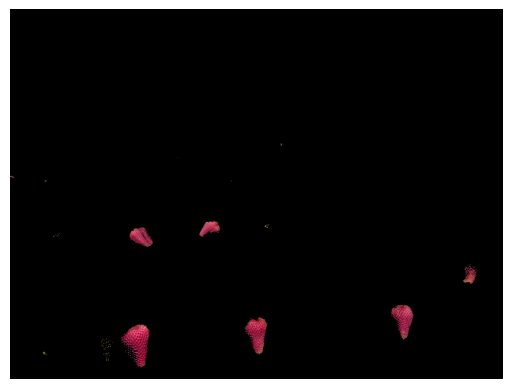

[2072.0, 1503.5, 1385.5, 870.5, 534.5, 388.5, 9.0, 6.5, 4.0, 3.0, 2.5, 1.5, 1.5, 1.0, 1.0]
Number of strawberries: 6
Largest strawberry area: 2072.0


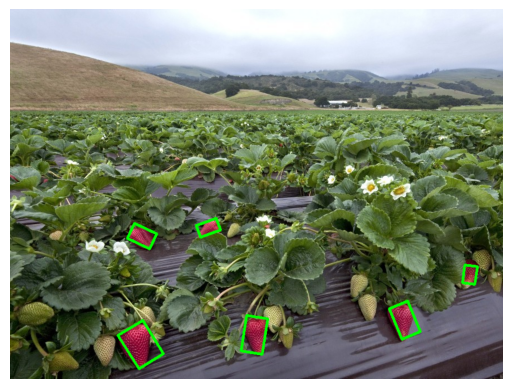

In [24]:
"""WRITE YOUR CODE HERE"""
strawberries = cv2.imread(STRAWBERRIES_PATH)
strawberries_hsv = cv2.cvtColor(strawberries, cv2.COLOR_BGR2HSV)

lower_red1 = np.array([0, 120, 120])
upper_red1 = np.array([20, 255, 255])
lower_red2 = np.array([150, 120, 120])
upper_red2 = np.array([179, 255, 255])

mask1 = cv2.inRange(strawberries_hsv, lower_red1, upper_red1)
mask2 = cv2.inRange(strawberries_hsv, lower_red2, upper_red2)
mask = mask1 | mask2

segmented_region_straw = cv2.bitwise_and(strawberries, strawberries, mask=mask)
strawberries_segmented_rgb = cv2.cvtColor(segmented_region_straw, cv2.COLOR_BGR2RGB)
plt.imshow(strawberries_segmented_rgb)
plt.axis("off")
plt.show()
result = strawberries.copy()
all_contours, filtered_contours, rotated_rects, box_points_for_drawing = find_rotated_rect(mask, pixel_area_threshold=100)

areas = sorted([cv2.contourArea(c) for c in all_contours], reverse=True)
print(areas[:15])

print("Number of strawberries:", len(filtered_contours))
largest_area = max(cv2.contourArea(c) for c in filtered_contours)
print("Largest strawberry area:", largest_area)

result = strawberries.copy()
cv2.drawContours(result, box_points_for_drawing, -1, (0, 255, 0), 3)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()



## Section 2: Geometric Feature Extraction with Hough Circles

### 1. How the Hough Circle Transform Works
Detecting circles using raw object boundaries (contours) can easily fail if an object has surface glare, shadows, or minor edge imperfections. To solve this, the **Hough Circle Transform** uses a voting system based on image gradients.

Every pixel along a circular edge has a gradient vector pointing directly toward or away from the center of the circle. The algorithm tracks these edge pixels and projects lines along their gradient directions. The location where the highest number of lines intersect (accumulate) "wins the vote" and is marked as a **circle center (x, y)**. Once a center is established, the algorithm calculates the most common distance from that center to the voting edge pixels to determine the **radius (r)**.

---

### 2. Crucial Preprocessing Steps
Before passing an image into the Hough detector, you must clean up the background to prevent noisy, false detections:

* **Grayscaling (`cv2.cvtColor`)**: Hough transforms evaluate structural intensity gradients (changes from light to dark), not color variations. When you look at an RGB image, color boundaries might look clear to human eyes, but the underlying mathematical intensity channels could be identical (e.g., a pure green shape next to a pure red shape of equal luminance yields a flat gradient). Reducing a 3-channel RGB image to a 1-channel grayscale canvas aligns the data to a single 0-255 luminance matrix, which drastically reduces computational memory overhead by two-thirds and simplifies edge-detection derivatives down to a single channel.

* **Gaussian Blurring (`cv2.GaussianBlur`)**: This is the most critical step. High-frequency textures inside a shape (such as the intricate texturing on a coin's face, reflections off a metal can rim, or printed text labels on top of a canister) generate sharp, tiny localized gradients. Without a blur, the internal Canny step interprets every microscopic scratch, letter, or shine line as a valid edge fragment. These noise fragments project false intersecting lines across the image, flooding the Hough accumulator grid with chaotic "ghost votes" and causing false positive circles or inaccurate radius calculations. 

Applying a spatial low-pass Gaussian filter mathematically smooths out these microscopic details by averaging local pixel neighborhoods using a bell-curve weighting function. This effectively dissolves high-frequency internal textures while preserving massive, macroscopic outer circular step-edges. For Hough transforms, always lean toward larger kernel configurations (such as `(11, 11)`, `(21, 21)`, or even higher depending on image resolution) than you would typically use for standard feature recognition.

use: 
```python
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
```
to convert to grayscale and then 
```python
cv2.GaussianBlur(gray, kernel_size, 0)
```
to blur the grayscale image.


---

### 3. Understanding `cv2.HoughCircles()` and its Arguments
Because finding circles across various radii is mathematically intense, OpenCV utilizes an optimized two-stage gradient method called `cv2.HOUGH_GRADIENT`. 

The function structure looks like this:
```python
circles = cv2.HoughCircles(image, method, dp, minDist, param1, param2, minRadius, maxRadius)
```


Key Arguments Broken Down:

- image: The 8-bit, single-channel grayscale input image.
- method: The detection routine. We almost always pass cv2.HOUGH_GRADIENT.
- dp: The inverse ratio of the accumulator resolution to the image resolution: we almost always pass 1.
- minDist: The minimum distance (in pixels) allowed between the centers of two detected circles. If this value is too small, multiple overlapping circles may be falsely detected around a single object. If it is too large, neighboring objects will be missed. It can be usefull given your prior knowledge of the object's size, if you know objects cannot overlap.
- param1: The higher threshold passed to the internal Canny edge detector (the lower threshold is automatically set to half of this value). A higher value filters out weaker image edges. you can explore between 50 and 200.
- param2: The accumulator threshold for the circle centers during the detection stage. This is your primary tuning knob!
	- It represents the minimum number of "votes" a center point must receive to be registered as a valid circle.
	- Lowering this value makes the detector more sensitive (picks up faint or heavily blurred circles, but increases false positives).
	- Raising this value makes the detector stricter (only returns highly defined circles).
- minRadius / maxRadius: The physical search boundaries (in pixels) for the circle radii. Narrowing this window drastically improves execution speed and prevents the algorithm from picking up tiny background noise or massive global image curves. If you have prior knowledge of the object's size, you can use that here.

cv2.HoughCircles() returns a 3D NumPy array containing the parameters of all detected circles. Its formal shape is (1, N, 3), where:
- 1 is an outer wrapper layer (due to historical OpenCV architecture constraints).
- N is the total number of circles detected in the image.
- 3 corresponds to the specific values describing each circle: [center_x, center_y, radius].

(If the algorithm does not find any circles matching your threshold criteria, it returns None)
Note that the circle information is returned in sub-pixel accuracy, so the center and radius values are floating-point numbers, rather than integers. to draw the detected circles on your image, you can use the following code:
```python
if circles is not None:
	for x, y, r in np.uint16(np.around(circles[0])):
		cv2.circle(img, (x, y), r, (0, 255, 0), 2)
```

In [19]:
COINS_PATH = "assets/coins.jpeg"

As a toy example, we'll try to detect coins on a table. load the image, convert it to rgb, and display it. then convert the image to grayscale, blur it, and display it, see what kernel size has what effect. Appy cv2.HoughCircles() on the blurred grayscale image and play around with the parameters. you can also try to apply the HoughCircles() function on the original un-blurred grayscale image to see how it performs. Note that the blurring kernel of cv2.GaussianBlur() can also be seen as part of the parameters that affects the results of the HoughCircles() function, so your settings of circle detection depends on the kernel size of your blurring.

finally, draw the detected circles on the original image. are they correctly detected? how many circles are detected, what is the largest radius? 

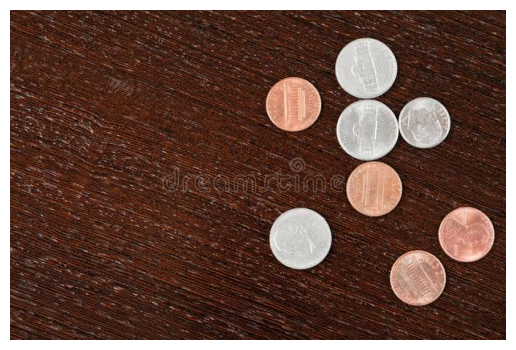

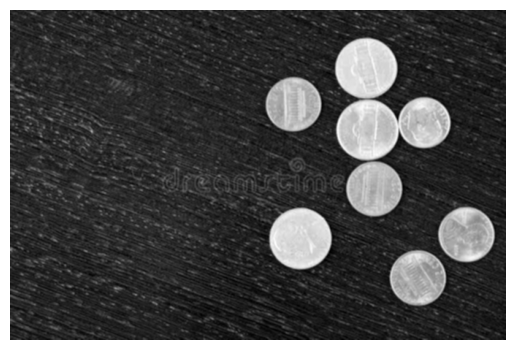

Number of circles: 8
Largest radius: 42


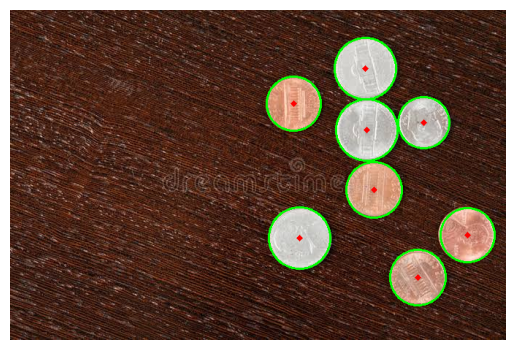

In [20]:
"""WRITE YOUR CODE HERE"""

circles = cv2.imread(COINS_PATH)

circles_rgb = cv2.cvtColor(circles, cv2.COLOR_BGR2RGB)
plt.imshow(circles_rgb)
plt.axis("off")
plt.show()

circles_gray = cv2.cvtColor(circles, cv2.COLOR_BGR2GRAY)
blurred_circles=cv2.GaussianBlur(circles_gray, (3, 3), 2)

plt.imshow(blurred_circles,cmap="gray")
plt.axis("off")
plt.show()

detected_circles = cv2.HoughCircles(blurred_circles, cv2.HOUGH_GRADIENT, dp=1, minDist=30, param1=100, param2=60, minRadius=10, maxRadius=60)

result = circles_rgb.copy()

if detected_circles is not None:
    detected_circles = np.uint16(np.around(detected_circles[0]))
    for x, y, r in detected_circles:
        cv2.circle(result, (x, y), r, (0, 255, 0), 2)
        cv2.circle(result, (x, y), 2, (255, 0, 0), 3)
    print("Number of circles:", len(detected_circles))
    print("Largest radius:", detected_circles[:, 2].max())
else:
    print("No circles detected")

plt.imshow(result); plt.axis("off"); plt.show()




## Section 3: Industry case study: detecting faulty cans

In this section we bring everything together to solve a real-world problem! 

A company fills tin (typical metallic look) cans (cilindrical) with powder and a (bright red) spoon (to scoop the powder). Before the powder is dropped in the can, a single spoon should be dropped in the can. The company has different automated ways to do this, but wants to quantify the accuracy of each method, as sometimes more than one spoon is dropped, or or no spoon is present in the can, or spoons fall outside a can on the conveyor belt. While someone could manually annotated the counts of how many cans have a single spoon, no spoon or multiple spoons, the company wants to automate this process as about a million cans are filled with powder every day. 

They have put a camera above the conveyor belt to capture the cans with a top-view after they exit the spoon-dropping machine. They would like to know how many cans have a single spoon, how many have no spoon, and how many have multiple spoons. they would also like to know how many spoons fell outside the cans on the conveyor belt. 

The method does not have to be perfect, but can you come up with an approach that could approximately solve this problem.
(After trying for a while individually, we can discuss the approaches you came up with in class.)

To help you get started: first, try to robustly detect most of the cans (partially outside image not needed). Then try to detect in the individuals cans whether there is a single spoon, no spoon, or multiple spoons. Finally, try to count the spoons that fell outside the cans.

In [21]:
CANS_PATH = "assets/cans.png"

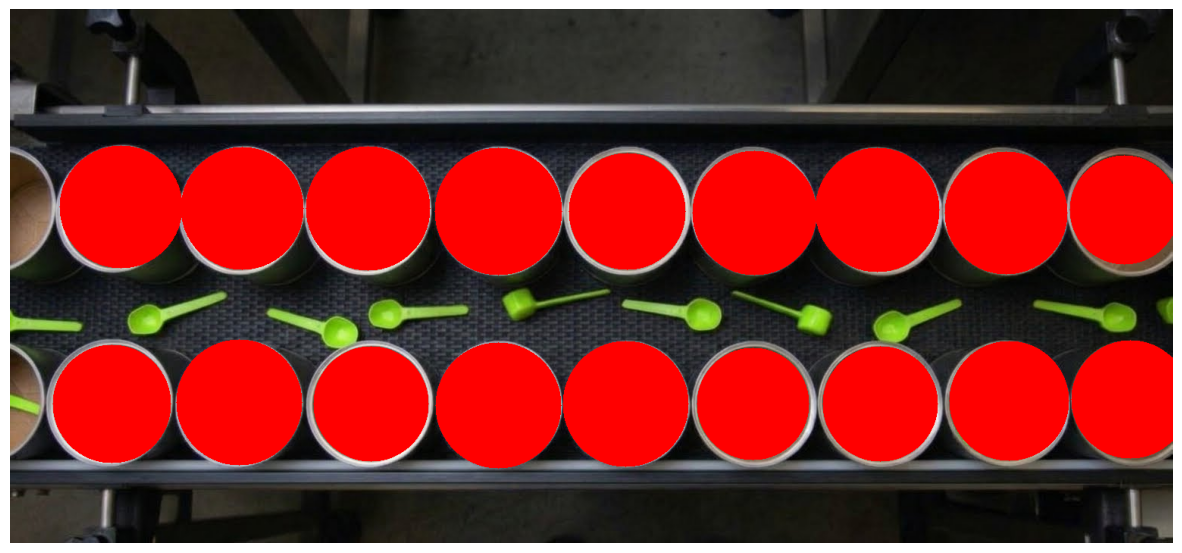

cans found: 18


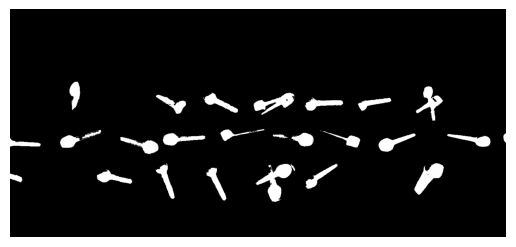

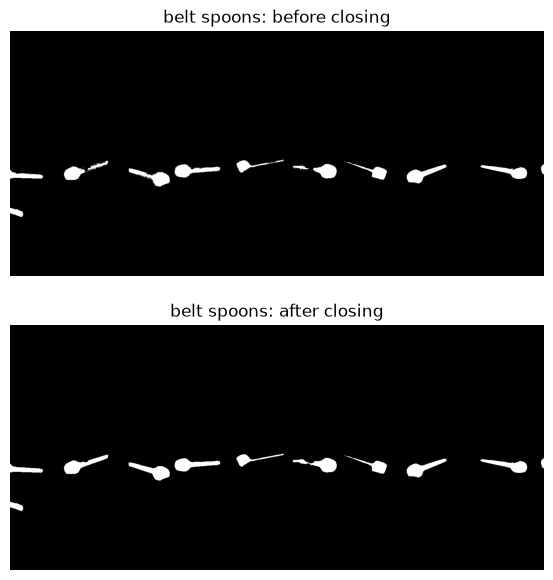

no spoon: 5
one spoon: 9
multiple spoons: 4
spoons outside cans: 9


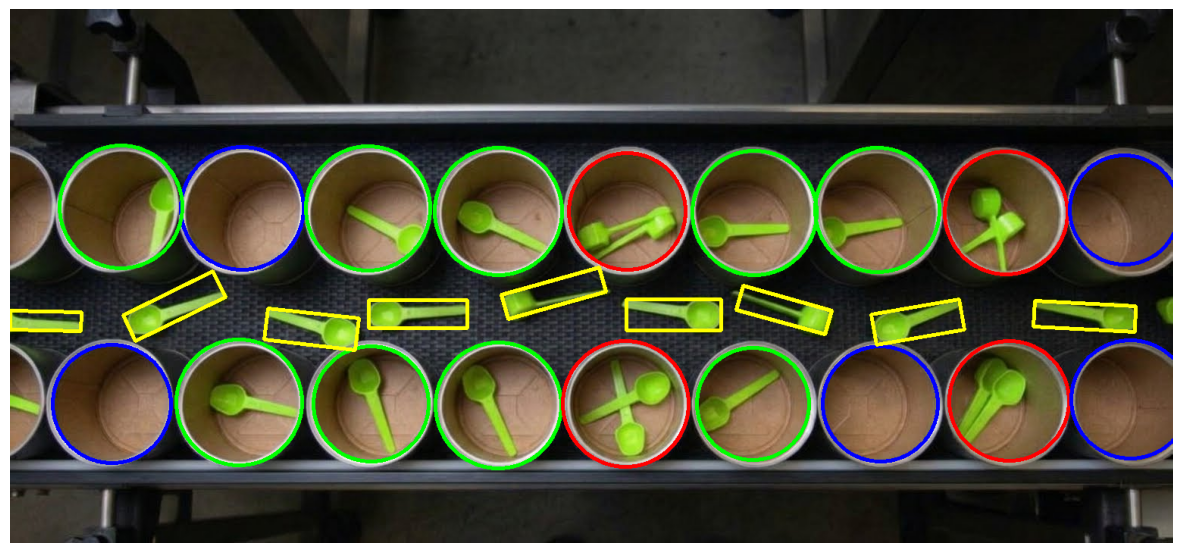

In [22]:
"""WRITE YOUR CODE HERE"""
cans = cv2.imread(CANS_PATH)

cans_rgb = cv2.cvtColor(cans, cv2.COLOR_BGR2RGB)
cans_gray = cv2.cvtColor(cans, cv2.COLOR_BGR2GRAY)
cans_hsv = cv2.cvtColor(cans, cv2.COLOR_BGR2HSV)
cans_blur = cv2.GaussianBlur(cans_gray, (9, 9), 2)

detected = cv2.HoughCircles(cans_blur, cv2.HOUGH_GRADIENT, dp=1, minDist=140, param1=50, param2=30, minRadius=65, maxRadius=95)
if detected is None:
    raise ValueError("No cans detected.")
detected = np.uint16(np.around(detected[0]))

check = cans_rgb.copy()
for x, y, r in detected:
    cv2.circle(check, (x, y), r, (255, 0, 0), -1)
plt.figure(figsize=(15, 7))
plt.imshow(check)
plt.axis("off"); plt.show()
print("cans found:", len(detected))

green_low = np.array([30, 120, 120])
green_high = np.array([80, 255, 255])
mask = cv2.inRange(cans_hsv, green_low, green_high)

plt.figure()
plt.imshow(mask, cmap="gray")
plt.axis("off")
plt.show()


no_spoon = one_spoon = multi_spoon = 0
result = cans_rgb.copy()
all_cans = np.zeros_like(mask)



for x, y, r in detected:
    circle_mask = np.zeros_like(mask)
    cv2.circle(circle_mask, (x, y), r, (255, 0, 0), -1)

    green = cv2.bitwise_and(mask, circle_mask)
    pixels = cv2.countNonZero(green)

    #print("Can:", x, y, "Green pixels:", pixels)

    if pixels < 500:
        no_spoon += 1
        color = (0, 0, 255) 
    elif pixels < 2600:
        one_spoon += 1
        color = (0, 255, 0)
    else:
        multi_spoon += 1
        color = (255, 0, 0)

    cv2.circle(result, (int(x), int(y)), int(r), color, 4) 
    cv2.circle(all_cans, (x, y), r + 10, 255, -1)

outside = mask & ~all_cans
close_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
outside_closed = cv2.morphologyEx(outside, cv2.MORPH_CLOSE, close_kernel)

plt.figure(figsize=(15, 7))
plt.subplot(2, 1, 1)
plt.imshow(outside, cmap="gray")
plt.title("belt spoons: before closing")
plt.axis("off")
plt.subplot(2, 1, 2)
plt.imshow(outside_closed, cmap="gray")
plt.title("belt spoons: after closing")
plt.axis("off")
plt.show()

_, belt_spoons, _, belt_boxes = find_rotated_rect(outside_closed, pixel_area_threshold=1000)


cv2.drawContours(result, belt_boxes, -1, (255, 255, 0), 3) 


print("no spoon:", no_spoon)
print("one spoon:", one_spoon)
print("multiple spoons:", multi_spoon)
print("spoons outside cans:", len(belt_spoons))

plt.figure(figsize=(15, 7))
plt.imshow(result)
plt.axis("off")
plt.show()



